<a href="https://colab.research.google.com/github/surajgade17/dpre1-ml-bioactivity/blob/main/DprE1_ML_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DprE1 bioactivity modelling: data limits and validation
Goal: test whether ML models can predict pIC50 for M. tuberculosis DprE1 inhibitors from public ChEMBL data, and how validation design changes the answer.
Data: ChEMBL target CHEMBL3804751, standard_type IC50. Retrieved on: [add date and ChEMBL release].
Random seed: 42 everywhere. SHAP is on hold because the models show no skill (see section 18).

# Environment Setup

This cell installs all required libraries and sets a random seed for reproducibility.

Tools used: RDKit (molecule handling), ChEMBL API client (data pull), XGBoost (ML model), SHAP (interpretability).

In [ ]:
# Install required libraries for this project
# rdkit handles molecule structures (SMILES, descriptors, fingerprints)
# chembl-webresource-client lets us pull bioactivity data directly from ChEMBL
# xgboost one of the ML algorithms we'll benchmark
# shap for interpretability (explains WHY the model predicts what it predicts)
!pip install rdkit chembl-webresource-client xgboost shap -q

# Import the libraries we just installed, plus core data tools
import pandas as pd
import numpy as np
from rdkit import Chem
from chembl_webresource_client.new_client import new_client

# Fixed seed so results are reproducible every time you re-run this notebook
SEED = 42
np.random.seed(SEED)

print("Setup complete")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 5.9 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


Setup complete


# Data Acquisation

Pulling raw data from DprE1 (CHEMBLE3804751) from ChEMBL.

This is a first look only - shape and a few rows, to confirm the pull works.

Cleaning happens in the next section, after we sanity-cheak what came back.




In [ ]:
# Target ChEMBL ID for DprE1 (Decaprenylphosphoryl-beta-D-ribose oxidase)
# Verified directly on ebi.ac.uk/chembl: single protein, M. tuberculosis H37Rv
TARGET_CHEMBL_ID = "CHEMBL3804751"

# 'activity' is the ChEMBL API endpoint for bioactivity data (IC50, Ki, etc.)
activity = new_client.activity

# Filter: only pull IC50 measurements for our target
# .only([...]) limits which columns come back, so we don't fetch unnecessary data
res = activity.filter(
    target_chembl_id=TARGET_CHEMBL_ID,
    standard_type="IC50"
).only([
    "molecule_chembl_id", "canonical_smiles",
    "standard_value", "standard_units", "standard_relation"
])

# Convert the API result into a pandas DataFrame (a table we can work with)
df_raw = pd.DataFrame(res)

# Quick sanity check: how many rows did we get, and what do they look like?
print(df_raw.shape)
df_raw.head()

(156, 8)


,canonical_smiles,molecule_chembl_id,relation,standard_relation,standard_units,standard_value,units,value
0,C[C@H]1COC2(CCN(c3nc(=O)c4cc(C(F)(F)F)cc(N=[N+...,CHEMBL3805705,=,=,nM,9600.0,uM,9.6
1,Cc1c(CCC(=O)N2CCCC2)c(=O)n2c([nH]c3ccccc32)c1C#N,CHEMBL4437244,=,=,nM,70.0,nM,70.0
2,O=C(O)c1nc2ccc(C(F)(F)F)cc2nc1NCc1ccc(C(F)(F)F...,CHEMBL4576609,=,=,nM,120.0,uM,0.12
3,COc1ccc(CNc2nc3cc(C(F)(F)F)ccc3nc2C(=O)O)cc1,CHEMBL1976041,=,=,nM,41.0,uM,0.041
4,O=C(O)c1nc2ccc(C(F)(F)F)cc2nc1NCc1ccc(F)cc1,CHEMBL1973996,=,=,nM,72.0,uM,0.072


In [ ]:
print(df_raw.head().to_string())

                                                   canonical_smiles molecule_chembl_id relation standard_relation standard_units standard_value units  value
0  C[C@H]1COC2(CCN(c3nc(=O)c4cc(C(F)(F)F)cc(N=[N+]=[N-])c4s3)CC2)O1      CHEMBL3805705        =                 =             nM         9600.0    uM    9.6
1                  Cc1c(CCC(=O)N2CCCC2)c(=O)n2c([nH]c3ccccc32)c1C#N      CHEMBL4437244        =                 =             nM           70.0    nM   70.0
2                O=C(O)c1nc2ccc(C(F)(F)F)cc2nc1NCc1ccc(C(F)(F)F)cc1      CHEMBL4576609        =                 =             nM          120.0    uM   0.12
3                      COc1ccc(CNc2nc3cc(C(F)(F)F)ccc3nc2C(=O)O)cc1      CHEMBL1976041        =                 =             nM           41.0    uM  0.041
4                       O=C(O)c1nc2ccc(C(F)(F)F)cc2nc1NCc1ccc(F)cc1      CHEMBL1973996        =                 =             nM           72.0    uM  0.072


## 1. Raw data inspection
156 records, 147 unique molecules. Relations: 140 '=', 10 '<', 6 '>'. Units: 148 nM, 8 ug/mL.
Decision: keep only exact ('=') values in nM.

In [ ]:
print(df_raw.shape)
print(df_raw["standard_relation"].value_counts(dropna=False))
print(df_raw["standard_units"].value_counts(dropna=False))
print(df_raw["molecule_chembl_id"].nunique(), "unique molecules")

(156, 8)
standard_relation
=    140
<     10
>      6
Name: count, dtype: int64
standard_units
nM         148
ug.mL-1      8
Name: count, dtype: int64
147 unique molecules


## 2. Cleaning
Funnel: 156 raw -> 140 after removing censored values ('<', '>') -> 132 after removing ug/mL rows -> 132 positive numeric values.
Censored values give only a bound, and ug/mL cannot be converted to nM without molecular weight.



In [ ]:
# Remember how many rows we started with, so we can compare at the end
n0 = len(df_raw)

# Step 1: remove rows with no structure or no activity value
df = df_raw.dropna(subset=["canonical_smiles", "standard_value"])
print("after dropna:", len(df))

# Step 2: keep only exact measurements ('=')
# '<' and '>' are censored: they give a bound, not a real value
df = df[df["standard_relation"] == "="]
print("after '=' only:", len(df))

# Step 3: keep only nM units
# ug/mL rows can't be converted to nM without molecular weight
# .copy() avoids Pandas warnings when we edit this filtered table
df = df[df["standard_units"] == "nM"].copy()
print("after nM only:", len(df))

# Step 4: make sure values are numbers; anything unreadable becomes NaN, then is dropped
df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")
df = df.dropna(subset=["standard_value"])

# Step 5: keep only positive values (the log in pIC50 is undefined for 0 or negatives)
df = df[df["standard_value"] > 0]
print("final:", len(df), "of", n0)

after dropna: 156
after '=' only: 140
after nM only: 132
final: 132 of 156


## 2b. Canonical SMILES, pIC50, duplicates
pIC50 = 9 - log10(IC50 in nM). One row per molecule (median of repeats).
Result: 130 unique compounds, pIC50 4.0 to 8.0, mean 6.04, SD 0.96.
129 compounds have one measurement and 1 has three, so assay noise cannot be estimated from this data.

In [ ]:
from rdkit import Chem

# Turn any SMILES into one standard form, so the same molecule
# written two different ways is recognized as identical
def canon(smi):
    m = Chem.MolFromSmiles(smi)          # parse the text into a molecule object
    return Chem.MolToSmiles(m) if m else None   # None if RDKit can't read it

df["canonical_smiles"] = df["canonical_smiles"].apply(canon)
df = df.dropna(subset=["canonical_smiles"])      # drop unreadable structures

# pIC50 = -log10(IC50 in molar). Our values are in nM (1e-9 M), hence 9 - log10(nM)
# Higher pIC50 = more potent compound
df["pIC50"] = 9 - np.log10(df["standard_value"])

# One row per unique molecule: take the median of repeat measurements
# and record how many repeats there were and how far apart they were
df_clean = df.groupby("canonical_smiles", as_index=False).agg(
    molecule_chembl_id=("molecule_chembl_id", "first"),
    pIC50=("pIC50", "median"),
    n_measurements=("pIC50", "size"),
    pIC50_spread=("pIC50", lambda s: s.max() - s.min()),
)

print("unique compounds:", len(df_clean))
print(df_clean["pIC50"].describe())
print("max spread:", df_clean["pIC50_spread"].max())

unique compounds: 130
count    130.000000
mean       6.041975
std        0.957729
min        4.000000
25%        5.275705
50%        6.013436
75%        6.915616
max        8.000000
Name: pIC50, dtype: float64
max spread: 0.07918124604762511


## 2c. Sanity checks
1 compound sits at pIC50 4.0 and 2 at 8.0, too few to matter. Cleaned data saved as dpre1_clean.csv.

In [ ]:
# How many repeats did each compound have? (expect almost all to be 1)
print(df_clean["n_measurements"].value_counts())

# Are many compounds stuck at the round-number edges?
# Many at 4.0 would suggest "inactive at top concentration", not a true IC50
print("pIC50 == 4.0:", (df_clean["pIC50"].round(3) == 4.0).sum())
print("pIC50 == 8.0:", (df_clean["pIC50"].round(3) == 8.0).sum())

# Save the cleaned data so you never have to repeat Section 2
df_clean.to_csv("dpre1_clean.csv", index=False)

n_measurements
1    129
3      1
Name: count, dtype: int64
pIC50 == 4.0: 1
pIC50 == 8.0: 2


## 3. Featurization
Three representations: 7 physicochemical descriptors, Morgan fingerprint (radius 2, 1024 bits), MACCS keys (167).
All 130 molecules parsed. The variance filter is applied later inside each training fold to avoid leakage.

In [ ]:
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator

# Convert every cleaned SMILES into an RDKit molecule object
mols = [Chem.MolFromSmiles(s) for s in df_clean["canonical_smiles"]]
print("molecules parsed:", sum(m is not None for m in mols), "of", len(mols))

# Representation 1: 7 simple physicochemical descriptors
desc_df = pd.DataFrame({
    "MolWt":         [Descriptors.MolWt(m) for m in mols],
    "LogP":          [Descriptors.MolLogP(m) for m in mols],
    "TPSA":          [Descriptors.TPSA(m) for m in mols],
    "HBD":           [Descriptors.NumHDonors(m) for m in mols],
    "HBA":           [Descriptors.NumHAcceptors(m) for m in mols],
    "RotB":          [Descriptors.NumRotatableBonds(m) for m in mols],
    "AromaticRings": [Descriptors.NumAromaticRings(m) for m in mols],
})

# Representation 2: Morgan fingerprint (1024 bits, radius 2)
# Each bit says "this substructure is present (1) or absent (0)"
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
fp_array = np.array([morgan_gen.GetFingerprintAsNumPy(m) for m in mols])

# Representation 3: MACCS keys (167 predefined substructure questions)
maccs_array = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols])

print("Descriptors:", desc_df.shape)
print("Morgan FP:  ", fp_array.shape)
print("MACCS:      ", maccs_array.shape)

molecules parsed: 130 of 130
Descriptors: (130, 7)
Morgan FP:   (130, 1024)
MACCS:       (130, 167)


has_nitro
False    112
True      18
Name: count, dtype: int64
           count      mean       std
has_nitro                           
False        112  6.037950  0.959009
True          18  6.067018  0.976943


/tmp/ipykernel_1313/3382878755.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[2].boxplot([df_clean.loc[~df_clean["has_nitro"], "pIC50"],


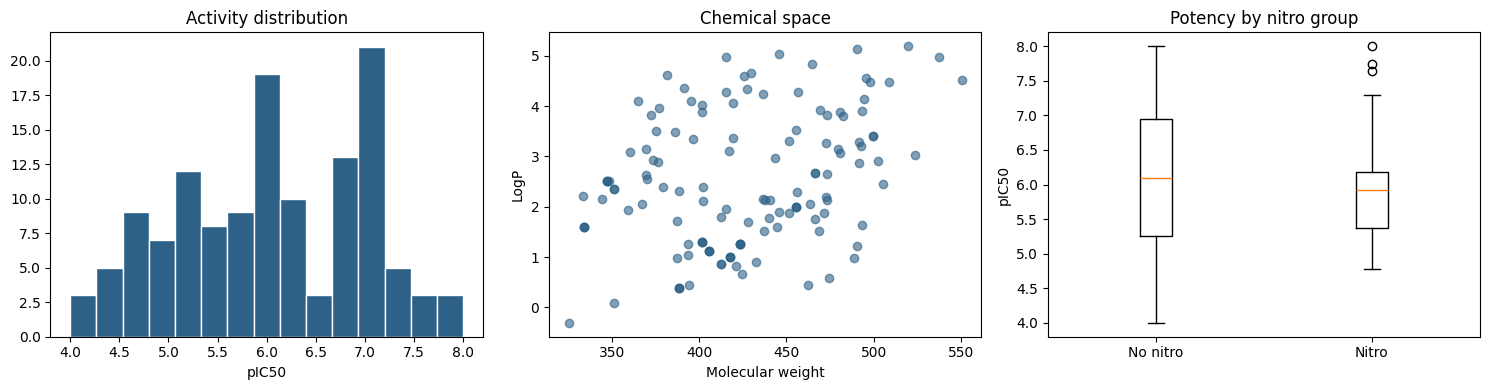

In [ ]:
import matplotlib.pyplot as plt

# Rough covalent-mechanism proxy: does the molecule contain a nitro group?
# (Covalent DprE1 inhibitors like BTZ043 carry a nitro group.)
# This is only a proxy, not a confirmed mechanism label.
nitro = Chem.MolFromSmarts("[N+](=O)[O-]")
df_clean["has_nitro"] = [m.HasSubstructMatch(nitro) for m in mols]
print(df_clean["has_nitro"].value_counts())
print(df_clean.groupby("has_nitro")["pIC50"].agg(["count", "mean", "std"]))

# Three quick plots to understand the dataset before modelling
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1) Activity distribution: roughly bell-shaped is good for regression
ax[0].hist(df_clean["pIC50"], bins=15, color="#2d6187", edgecolor="white")
ax[0].set_xlabel("pIC50"); ax[0].set_title("Activity distribution")

# 2) Chemical space: how spread out are size and lipophilicity?
ax[1].scatter(desc_df["MolWt"], desc_df["LogP"], alpha=0.6, color="#2d6187")
ax[1].set_xlabel("Molecular weight"); ax[1].set_ylabel("LogP")
ax[1].set_title("Chemical space")

# 3) Do nitro and non-nitro compounds differ in potency?
ax[2].boxplot([df_clean.loc[~df_clean["has_nitro"], "pIC50"],
               df_clean.loc[df_clean["has_nitro"], "pIC50"]],
              labels=["No nitro", "Nitro"])
ax[2].set_ylabel("pIC50"); ax[2].set_title("Potency by nitro group")

plt.tight_layout()
plt.savefig("eda_summary.png", dpi=300)
plt.show()

In [ ]:
from rdkit.Chem.Scaffolds import MurckoScaffold

# Murcko scaffold = ring system plus linkers, side chains stripped off
# Close analogs share a scaffold, so they must stay together in the split
df_clean["scaffold"] = [MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols]

# How many distinct scaffolds, and how big is each family?
sizes = df_clean["scaffold"].value_counts()
print("unique scaffolds:", len(sizes))
print(sizes.head(5))
print("singletons:", (sizes == 1).sum())

unique scaffolds: 50
scaffold
O=C(CN1C(=O)NC(c2ccccc2)C1=O)c1ccccc1    47
O=c1nc(N2CCN(CC3CCCCC3)CC2)sc2ccccc12    15
c1ccc(CNc2cnc3ccccc3n2)cc1                7
O=c1nc(N2CCC3(CC2)OCCO3)sc2ccccc12        7
O=C(CN1C(=O)NC(c2ccccc2)C1=O)c1ccccn1     3
Name: count, dtype: int64
singletons: 40


In [ ]:
# Do the big scaffold families differ in potency? (explains the two-humped histogram?)
top = df_clean["scaffold"].value_counts().head(4).index
for s in top:
    sub = df_clean[df_clean["scaffold"] == s]["pIC50"]
    print(f"n={len(sub):3d}  mean={sub.mean():.2f}  sd={sub.std():.2f}  {s}")
rest = df_clean[~df_clean["scaffold"].isin(top)]["pIC50"]
print(f"n={len(rest):3d}  mean={rest.mean():.2f}  sd={rest.std():.2f}  all other scaffolds")

n= 47  mean=6.24  sd=0.81  O=C(CN1C(=O)NC(c2ccccc2)C1=O)c1ccccc1
n= 15  mean=6.08  sd=0.87  O=c1nc(N2CCN(CC3CCCCC3)CC2)sc2ccccc12
n=  7  mean=7.15  sd=0.15  c1ccc(CNc2cnc3ccccc3n2)cc1
n=  7  mean=5.00  sd=0.64  O=c1nc(N2CCC3(CC2)OCCO3)sc2ccccc12
n= 54  mean=5.85  sd=1.01  all other scaffolds


In [ ]:
from collections import defaultdict

# Group compound row-numbers by scaffold
groups = defaultdict(list)
for i, s in enumerate(df_clean["scaffold"]):
    groups[s].append(i)

# Biggest families first, so train gets the major series
ordered = sorted(groups.values(), key=len, reverse=True)
train_target = int(0.8 * len(df_clean))      # aim for 80% train

train_idx, test_idx = [], []
for g in ordered:
    if len(train_idx) + len(g) <= train_target:
        train_idx.extend(g)                  # whole family goes to train
    else:
        test_idx.extend(g)                   # whole family goes to test

# Leakage check: no scaffold may appear on both sides
tr = set(df_clean.loc[train_idx, "scaffold"])
te = set(df_clean.loc[test_idx, "scaffold"])
print("train:", len(train_idx), " test:", len(test_idx))
print("shared scaffolds (must be 0):", len(tr & te))

# Is the test set similar in potency range to train?
print(df_clean.loc[train_idx, "pIC50"].describe()[["mean", "std", "min", "max"]])
print(df_clean.loc[test_idx, "pIC50"].describe()[["mean", "std", "min", "max"]])

train: 104  test: 26
shared scaffolds (must be 0): 0
mean    6.044618
std     0.906290
min     4.000000
max     8.000000
Name: pIC50, dtype: float64
mean    6.031401
std     1.161394
min     4.384681
max     8.000000
Name: pIC50, dtype: float64


In [ ]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

SEED = 42
y = df_clean["pIC50"].values
y_train, y_test = y[train_idx], y[test_idx]

# Remove near-constant fingerprint bits, learned from TRAIN only
# (fitting on all data would let test information leak into training)
sel = VarianceThreshold(threshold=0.01)
X_train = sel.fit_transform(fp_array[train_idx])
X_test = sel.transform(fp_array[test_idx])
print("bits kept:", X_train.shape[1], "of", fp_array.shape[1])

# Baseline: always predict the training mean. Any real model must beat this.
base = np.full(len(y_test), y_train.mean())
print("baseline  R2:", round(r2_score(y_test, base), 3),
      " RMSE:", round(np.sqrt(mean_squared_error(y_test, base)), 3))

# Random Forest: many decision trees averaged together
rf = RandomForestRegressor(n_estimators=300, random_state=SEED)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print("RF        R2:", round(r2_score(y_test, pred), 3),
      " RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

bits kept: 287 of 1024
baseline  R2: -0.0  RMSE: 1.139
RF        R2: -0.159  RMSE: 1.226


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

groups = df_clean["scaffold"].values        # molecules sharing a scaffold stay together
feats = {"Morgan": fp_array, "MACCS": maccs_array, "Descriptors": desc_df.values}

# 20 different random scaffold-grouped 80/20 splits (same splits reused for every model)
# Note: test_size counts scaffold GROUPS, so test size in compounds varies per split
gss = GroupShuffleSplit(n_splits=20, test_size=0.2, random_state=SEED)
splits = list(gss.split(fp_array, y, groups))

def evaluate(make_model, X):
    scores = []
    for tr, te in splits:
        m = make_model()
        m.fit(X[tr], y[tr])
        scores.append(r2_score(y[te], m.predict(X[te])))
    return np.array(scores)

# Baseline: predict the training mean every time
base = evaluate(lambda: DummyRegressor(strategy="mean"), fp_array)
print(f"Baseline     R2 = {base.mean():.3f} +/- {base.std():.3f}")

for name, X in feats.items():
    # Pipeline: drop near-constant features inside each split, then Random Forest
    make = lambda: Pipeline([
        ("vt", VarianceThreshold(threshold=0.01)),
        ("rf", RandomForestRegressor(n_estimators=200, random_state=SEED)),
    ])
    s = evaluate(make, X)
    wins = (s > base).mean()          # fraction of splits where the model beats baseline
    print(f"{name:12s} R2 = {s.mean():.3f} +/- {s.std():.3f}   beats baseline in {wins:.0%} of splits")

Baseline     R2 = -0.155 +/- 0.245
Morgan       R2 = -0.301 +/- 0.315   beats baseline in 25% of splits
MACCS        R2 = -0.126 +/- 0.231   beats baseline in 45% of splits
Descriptors  R2 = -0.185 +/- 0.344   beats baseline in 50% of splits


In [ ]:
# Search ChEMBL for every target record that mentions DprE1
targets = pd.DataFrame(new_client.target.search("DprE1"))
print(targets[["target_chembl_id", "pref_name", "organism", "target_type"]].to_string())

# For each, count how many IC50 measurements exist
for tid in targets["target_chembl_id"]:
    try:
        n = new_client.activity.filter(target_chembl_id=tid, standard_type="IC50").count()
        print(tid, "IC50 records:", n)
    except Exception as e:
        print(tid, "failed:", e)

  target_chembl_id                                   pref_name                                                 organism     target_type
0    CHEMBL3797019  Decaprenylphosphoryl-beta-D-ribose oxidase  Mycobacterium smegmatis (strain ATCC 700084 / mc(2)155)  SINGLE PROTEIN
1    CHEMBL3804751  Decaprenylphosphoryl-beta-D-ribose oxidase   Mycobacterium tuberculosis (strain ATCC 25618 / H37Rv)  SINGLE PROTEIN
CHEMBL3797019 failed: 'QuerySet' object has no attribute 'count'
CHEMBL3804751 failed: 'QuerySet' object has no attribute 'count'


In [ ]:
# Pull IC50 data for the M. smegmatis DprE1 record
res2 = new_client.activity.filter(
    target_chembl_id="CHEMBL3797019", standard_type="IC50"
).only(["molecule_chembl_id", "canonical_smiles",
        "standard_value", "standard_units", "standard_relation"])
df_sm = pd.DataFrame(res2)
print("M. smegmatis IC50 rows:", df_sm.shape[0])

if df_sm.shape[0] > 0:
    # Same filters as before: exact values, nM units
    ok = df_sm[(df_sm["standard_relation"] == "=") & (df_sm["standard_units"] == "nM")]
    print("usable (= and nM):", len(ok))
    print("unique molecules:", ok["molecule_chembl_id"].nunique())
    # How many are already in your Mtb dataset? Only the rest would be new
    overlap = ok["molecule_chembl_id"].isin(df_clean["molecule_chembl_id"]).sum()
    print("already in your Mtb set:", overlap)

M. smegmatis IC50 rows: 1
usable (= and nM): 1
unique molecules: 1
already in your Mtb set: 1


In [ ]:
from sklearn.model_selection import ShuffleSplit

# 20 ordinary random 80/20 splits (analogs from one series can land on both sides)
rand_splits = list(ShuffleSplit(n_splits=20, test_size=0.2, random_state=SEED).split(fp_array))

# Same scoring loop as before, but it accepts any list of splits
def evaluate_on(split_list, make_model, X):
    scores = []
    for tr, te in split_list:
        m = make_model()
        m.fit(X[tr], y[tr])
        scores.append(r2_score(y[te], m.predict(X[te])))
    return np.array(scores)

for name, X in feats.items():
    make = lambda: Pipeline([
        ("vt", VarianceThreshold(threshold=0.01)),
        ("rf", RandomForestRegressor(n_estimators=200, random_state=SEED)),
    ])
    r = evaluate_on(rand_splits, make, X)   # random splits
    s = evaluate_on(splits, make, X)        # scaffold splits from Cell 11
    print(f"{name:12s} random R2 = {r.mean():.3f} +/- {r.std():.3f} | scaffold R2 = {s.mean():.3f} +/- {s.std():.3f}")

Morgan       random R2 = 0.027 +/- 0.199 | scaffold R2 = -0.301 +/- 0.315
MACCS        random R2 = 0.072 +/- 0.216 | scaffold R2 = -0.126 +/- 0.231
Descriptors  random R2 = -0.031 +/- 0.233 | scaffold R2 = -0.185 +/- 0.344


In [ ]:
from rdkit import DataStructs

# Fingerprint objects that RDKit can compare directly (Tanimoto similarity)
fps = [morgan_gen.GetFingerprint(m) for m in mols]

nn_sim, nn_y = [], []
for i, f in enumerate(fps):
    sims = np.array(DataStructs.BulkTanimotoSimilarity(f, fps))
    sims[i] = -1                      # exclude the molecule itself
    j = sims.argmax()                 # its single most similar neighbour
    nn_sim.append(sims[j])
    nn_y.append(y[j])
nn_sim, nn_y = np.array(nn_sim), np.array(nn_y)

print("median nearest-neighbour similarity:", round(float(np.median(nn_sim)), 2))
# Does a molecule's potency match its closest neighbour's potency?
for cut in [0.0, 0.5, 0.7]:
    mask = nn_sim >= cut
    r = np.corrcoef(y[mask], nn_y[mask])[0, 1]
    print(f"similarity >= {cut}: n={mask.sum()}, correlation with neighbour pIC50 = {r:.2f}")

median nearest-neighbour similarity: 0.79
similarity >= 0.0: n=130, correlation with neighbour pIC50 = 0.42
similarity >= 0.5: n=129, correlation with neighbour pIC50 = 0.42
similarity >= 0.7: n=117, correlation with neighbour pIC50 = 0.39


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# Morgan bits as True/False; "jaccard" distance on bits = 1 - Tanimoto similarity
X_bits = fp_array.astype(bool)

# k=5 chosen in advance (not tuned); distance weighting = closer analogs count more
make_knn = lambda: KNeighborsRegressor(n_neighbors=5, metric="jaccard",
                                       weights="distance", algorithm="brute")

r = evaluate_on(rand_splits, make_knn, X_bits)
s = evaluate_on(splits, make_knn, X_bits)
print(f"kNN (k=5, Tanimoto)  random R2 = {r.mean():.3f} +/- {r.std():.3f} | scaffold R2 = {s.mean():.3f} +/- {s.std():.3f}")

kNN (k=5, Tanimoto)  random R2 = 0.086 +/- 0.213 | scaffold R2 = -0.249 +/- 0.251


In [ ]:
# Baseline on the random splits (needed for a fair comparison)
base_r = evaluate_on(rand_splits, lambda: DummyRegressor(strategy="mean"), fp_array)
print(f"Baseline  random R2 = {base_r.mean():.3f} +/- {base_r.std():.3f}")

# How often does each model beat the baseline, split by split?
# (Compared on the SAME splits, so the comparison is paired)
make_rf = lambda: Pipeline([("vt", VarianceThreshold(threshold=0.01)),
                            ("rf", RandomForestRegressor(n_estimators=200, random_state=SEED))])
for name, X in feats.items():
    r = evaluate_on(rand_splits, make_rf, X)
    print(f"RF {name:12s} beats baseline in {(r > base_r).mean():.0%} of random splits")

knn_r = evaluate_on(rand_splits, make_knn, X_bits)
knn_s = evaluate_on(splits, make_knn, X_bits)
print(f"kNN beats baseline in {(knn_r > base_r).mean():.0%} of random splits")
print(f"kNN beats baseline in {(knn_s > base).mean():.0%} of scaffold splits")

Baseline  random R2 = -0.072 +/- 0.085
RF Morgan       beats baseline in 70% of random splits
RF MACCS        beats baseline in 70% of random splits
RF Descriptors  beats baseline in 65% of random splits
kNN beats baseline in 70% of random splits
kNN beats baseline in 45% of scaffold splits


In [ ]:
# Same Mtb DprE1 IC50 data, this time keeping assay and paper information
res = new_client.activity.filter(
    target_chembl_id="CHEMBL3804751", standard_type="IC50"
).only(["molecule_chembl_id", "canonical_smiles", "standard_value",
        "standard_units", "standard_relation",
        "assay_chembl_id", "assay_type", "assay_description",
        "document_chembl_id"])
df_src = pd.DataFrame(res)
print(df_src.shape)

# Assay type: B = binding/biochemical, F = functional, others possible
print(df_src["assay_type"].value_counts(dropna=False))
print(df_src["assay_chembl_id"].nunique(), "assays;",
      df_src["document_chembl_id"].nunique(), "source documents")

# How many records does each source paper contribute?
print(df_src["document_chembl_id"].value_counts())
df_src.to_csv("dpre1_raw_with_sources.csv", index=False)

(156, 13)
assay_type
B    156
Name: count, dtype: int64
17 assays; 12 source documents
document_chembl_id
CHEMBL4402609    71
CHEMBL4371005    22
CHEMBL4706562    16
CHEMBL5143519    12
CHEMBL5046318    12
CHEMBL4831479     7
CHEMBL6074635     6
CHEMBL4828770     3
CHEMBL5528009     3
CHEMBL5260858     2
CHEMBL3804812     1
CHEMBL5154717     1
Name: count, dtype: int64


In [ ]:
# Look up title, journal, year and DOI for each source document
ids = list(df_src["document_chembl_id"].dropna().unique())
docs = pd.DataFrame(new_client.document.filter(document_chembl_id__in=ids)
                    .only(["document_chembl_id", "title", "journal", "year", "doi"]))
print(docs.sort_values("year").to_string())

   document_chembl_id                             doi            journal                                                                                                                      title  year
0       CHEMBL3804812  10.1021/acsmedchemlett.5b00424  ACS Med Chem Lett      Design, Syntheses, and Anti-TB Activity of 1,3-Benzothiazinone Azide and Click Chemistry Products Inspired by BTZ043.  2016
1       CHEMBL4371005    10.1021/acs.jmedchem.8b00281         J Med Chem                                  Overview of the Development of DprE1 Inhibitors for Combating the Menace of Tuberculosis.  2018
2       CHEMBL4402609    10.1021/acs.jmedchem.0c00107         J Med Chem         Optimization of Hydantoins as Potent Antimycobacterial Decaprenylphosphoryl-β-d-Ribose Oxidase (DprE1) Inhibitors.  2020
3       CHEMBL4706562    10.1016/j.ejmech.2020.112773     Eur J Med Chem                                 Design, synthesis and evaluation of covalent inhibitors of DprE1 as antitubercular agen

In [ ]:
# Attach the source paper to each cleaned compound
src = df_src[["molecule_chembl_id", "document_chembl_id"]].drop_duplicates("molecule_chembl_id")
m = df_clean[["molecule_chembl_id", "scaffold", "pIC50"]].merge(
    src, on="molecule_chembl_id", how="left")

# Which papers does each of the 4 biggest scaffold families come from?
top = df_clean["scaffold"].value_counts().head(4).index
for s in top:
    sub = m[m["scaffold"] == s]
    print(s[:35], "->", sub["document_chembl_id"].value_counts().to_dict())

# Do papers differ in average potency?
print(m.groupby("document_chembl_id")["pIC50"].agg(["count", "mean", "std"]).round(2))

O=C(CN1C(=O)NC(c2ccccc2)C1=O)c1cccc -> {'CHEMBL4402609': 47}
O=c1nc(N2CCN(CC3CCCCC3)CC2)sc2ccccc -> {'CHEMBL4706562': 13, 'CHEMBL5046318': 2}
c1ccc(CNc2cnc3ccccc3n2)cc1 -> {'CHEMBL4371005': 7}
O=c1nc(N2CCC3(CC2)OCCO3)sc2ccccc12 -> {'CHEMBL6074635': 6, 'CHEMBL3804812': 1}
                    count  mean   std
document_chembl_id                   
CHEMBL3804812           1  5.02   NaN
CHEMBL4371005          12  7.06  0.45
CHEMBL4402609          71  6.08  0.87
CHEMBL4706562          14  5.93  0.86
CHEMBL4828770           3  5.94  0.23
CHEMBL4831479           1  7.28   NaN
CHEMBL5046318          11  5.62  0.69
CHEMBL5143519           9  5.42  1.29
CHEMBL5528009           2  7.69  0.08
CHEMBL6074635           6  4.99  0.70


In [ ]:
# Flag records that come from documents whose titles read like reviews (verify by opening them)
review_docs = ["CHEMBL4371005", "CHEMBL5260858"]
m["from_review"] = m["document_chembl_id"].isin(review_docs)
print(m["from_review"].value_counts())
print(m.groupby("from_review")["pIC50"].agg(["count", "mean", "std"]).round(2))

from_review
False    118
True      12
Name: count, dtype: int64
             count  mean   std
from_review                   
False          118  5.94  0.94
True            12  7.06  0.45


In [ ]:
# 1) How much of the pIC50 variance does "which paper" alone explain?
assert len(m) == len(df_clean)
grp_mean = m.groupby("document_chembl_id")["pIC50"].transform("mean")
eta2 = 1 - ((m["pIC50"] - grp_mean)**2).sum() / ((m["pIC50"] - m["pIC50"].mean())**2).sum()
print(f"variance explained by source paper: {eta2:.0%} (slightly overstated: 2 papers have 1 compound)")

# 2) Sensitivity run: repeat the whole evaluation without review-derived compounds
review_docs = ["CHEMBL4371005", "CHEMBL5260858"]
keep = ~m["document_chembl_id"].isin(review_docs).values

def run_all(mask, label):
    idx = np.where(mask)[0]
    yy, g = y[idx], groups[idx]
    sc = list(GroupShuffleSplit(n_splits=20, test_size=0.2, random_state=SEED).split(idx, yy, g))
    rd = list(ShuffleSplit(n_splits=20, test_size=0.2, random_state=SEED).split(idx))
    def ev(sp, mk, X):
        out = []
        for tr, te in sp:
            mdl = mk(); mdl.fit(X[tr], yy[tr])
            out.append(r2_score(yy[te], mdl.predict(X[te])))
        return np.array(out)
    models = {"Baseline": (lambda: DummyRegressor(strategy="mean"), fp_array[idx]),
              "RF Morgan": (make_rf, fp_array[idx]),
              "RF MACCS":  (make_rf, maccs_array[idx]),
              "RF Descr":  (make_rf, desc_df.values[idx]),
              "kNN":       (make_knn, X_bits[idx])}
    print(label, "n =", len(idx))
    for name, (mk, X) in models.items():
        r, s = ev(rd, mk, X), ev(sc, mk, X)
        print(f"{name:10s} random {r.mean():.3f}+/-{r.std():.3f} | scaffold {s.mean():.3f}+/-{s.std():.3f}")

run_all(keep, "Without review-derived records")

variance explained by source paper: 28% (slightly overstated: 2 papers have 1 compound)
Without review-derived records n = 118
Baseline   random -0.072+/-0.072 | scaffold -0.177+/-0.206
RF Morgan  random 0.017+/-0.299 | scaffold -0.166+/-0.274
RF MACCS   random -0.039+/-0.264 | scaffold -0.142+/-0.291
RF Descr   random -0.082+/-0.256 | scaffold -0.148+/-0.401
kNN        random 0.027+/-0.289 | scaffold -0.163+/-0.319


In [ ]:
import json
from sklearn.metrics import mean_absolute_error

def full_report(mask, dataset_name):
    idx = np.where(mask)[0]
    yy, g = y[idx], groups[idx]
    sp = {"scaffold": list(GroupShuffleSplit(n_splits=20, test_size=0.2, random_state=SEED).split(idx, yy, g)),
          "random":   list(ShuffleSplit(n_splits=20, test_size=0.2, random_state=SEED).split(idx))}
    models = {"Baseline":  (lambda: DummyRegressor(strategy="mean"), fp_array[idx]),
              "RF Morgan": (make_rf, fp_array[idx]),
              "RF MACCS":  (make_rf, maccs_array[idx]),
              "RF Descr":  (make_rf, desc_df.values[idx]),
              "kNN":       (make_knn, X_bits[idx])}
    rows = []
    for stype, lst in sp.items():
        for k, (tr, te) in enumerate(lst):
            for name, (mk, X) in models.items():
                mdl = mk(); mdl.fit(X[tr], yy[tr]); p = mdl.predict(X[te])
                rows.append(dict(dataset=dataset_name, split_type=stype, split_id=k, model=name,
                                 n_train=len(tr), n_test=len(te),
                                 R2=r2_score(yy[te], p),
                                 RMSE=np.sqrt(mean_squared_error(yy[te], p)),
                                 MAE=mean_absolute_error(yy[te], p)))
    # Record exactly which compounds were in each test set (for reproducibility)
    assign = {stype: [idx[te].tolist() for _, te in lst] for stype, lst in sp.items()}
    return pd.DataFrame(rows), assign

res_a, asg_a = full_report(np.ones(len(df_clean), dtype=bool), "all_130")
res_b, asg_b = full_report(keep, "no_review_118")
res = pd.concat([res_a, res_b], ignore_index=True)
res.to_csv("model_eval_all_splits.csv", index=False)
json.dump({"all_130": asg_a, "no_review_118": asg_b}, open("split_assignments.json", "w"))

summ = res.groupby(["dataset", "split_type", "model"]).agg(
    R2_mean=("R2", "mean"), R2_sd=("R2", "std"),
    RMSE=("RMSE", "mean"), MAE=("MAE", "mean"),
    n_test_min=("n_test", "min"), n_test_max=("n_test", "max")).round(3)
print(summ.to_string())

                                    R2_mean  R2_sd   RMSE    MAE  n_test_min  n_test_max
dataset       split_type model                                                          
all_130       random     Baseline    -0.072  0.087  0.960  0.812          26          26
                         RF Descr    -0.031  0.239  0.937  0.733          26          26
                         RF MACCS     0.072  0.222  0.888  0.673          26          26
                         RF Morgan    0.027  0.204  0.909  0.706          26          26
                         kNN          0.086  0.218  0.884  0.678          26          26
              scaffold   Baseline    -0.155  0.252  0.967  0.824          11          76
                         RF Descr    -0.185  0.353  0.973  0.797          11          76
                         RF MACCS    -0.126  0.237  0.952  0.800          11          76
                         RF Morgan   -0.301  0.323  1.024  0.875          11          76
                     

In [ ]:
def fixed_scaffold_splits(g, n_splits=20, test_frac=0.2, max_group=15, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(g)
    target = int(test_frac * n)
    # positions of compounds in each scaffold group; keep only groups <= max_group
    members = pd.Series(range(n)).groupby(np.asarray(g)).apply(list)
    small = [pos for pos in members if len(pos) <= max_group]
    out = []
    for _ in range(n_splits):
        test = []
        for k in rng.permutation(len(small)):
            grp = small[k]
            if len(test) + len(grp) <= target + 2:   # stay close to the target size
                test.extend(grp)
            if len(test) >= target:
                break
        te = np.array(sorted(test))
        out.append((np.setdiff1d(np.arange(n), te), te))
    return out

def eval_fixed(mask, label):
    idx = np.where(mask)[0]
    yy, g = y[idx], groups[idx]
    sp = fixed_scaffold_splits(g)
    models = {"Baseline":  (lambda: DummyRegressor(strategy="mean"), fp_array[idx]),
              "RF Morgan": (make_rf, fp_array[idx]),
              "RF MACCS":  (make_rf, maccs_array[idx]),
              "RF Descr":  (make_rf, desc_df.values[idx]),
              "kNN":       (make_knn, X_bits[idx])}
    rows = []
    for k, (tr, te) in enumerate(sp):
        for name, (mk, X) in models.items():
            mdl = mk(); mdl.fit(X[tr], yy[tr]); p = mdl.predict(X[te])
            rows.append(dict(dataset=label, split_type="scaffold_fixed", split_id=k, model=name,
                             n_train=len(tr), n_test=len(te), R2=r2_score(yy[te], p),
                             RMSE=np.sqrt(mean_squared_error(yy[te], p)),
                             MAE=mean_absolute_error(yy[te], p)))
    return pd.DataFrame(rows)

res_f = pd.concat([eval_fixed(np.ones(len(df_clean), dtype=bool), "all_130"),
                   eval_fixed(keep, "no_review_118")], ignore_index=True)
res_f.to_csv("model_eval_scaffold_fixed.csv", index=False)
print(res_f.groupby(["dataset", "model"]).agg(
    R2_mean=("R2", "mean"), R2_sd=("R2", "std"), MAE=("MAE", "mean"),
    n_test_min=("n_test", "min"), n_test_max=("n_test", "max")).round(3).to_string())

                         R2_mean  R2_sd    MAE  n_test_min  n_test_max
dataset       model                                                   
all_130       Baseline    -0.076  0.101  0.860          26          28
              RF Descr    -0.127  0.306  0.843          26          28
              RF MACCS    -0.152  0.271  0.842          26          28
              RF Morgan   -0.292  0.418  0.902          26          28
              kNN         -0.218  0.237  0.876          26          28
no_review_118 Baseline    -0.169  0.180  0.845          23          25
              RF Descr    -0.400  0.345  0.894          23          25
              RF MACCS    -0.294  0.277  0.850          23          25
              RF Morgan   -0.275  0.286  0.854          23          25
              kNN         -0.359  0.330  0.872          23          25


In [ ]:
asg_f = {lab: [idx[te].tolist() for _, te in fixed_scaffold_splits(groups[idx])]
         for lab, idx in {"all_130": np.arange(len(df_clean)),
                          "no_review_118": np.where(keep)[0]}.items()}
json.dump(asg_f, open("split_assignments_fixed.json", "w"))